# Deep Learning 2026 - Assignment 1, Part 3: Deep versus wide networks
## Exercise 1: noisy-XOR data, model, training loop and plots

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

### 1. Data generation class
Each point is a cluster centre (m1, m2) in {0,1}^2 plus Gaussian noise with std `s`.
The label is `m1 xor m2`.

In [2]:
class NoisyXOR(Dataset):
    def __init__(self, n_samples=500, s=0.1):
        # pick one of the four cluster centres at random for every sample
        m = torch.randint(0, 2, (n_samples, 2)).float()
        # add Gaussian noise with standard deviation s
        self.x = m + s * torch.randn(n_samples, 2)
        # label = m1 xor m2 (1 if the two centre coordinates differ), shape (n, 1)
        self.y = (m[:, 0] != m[:, 1]).float().unsqueeze(1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]

### 2. Model class
A feed-forward network with a chosen number of hidden layers and hidden units per layer.
Hidden activations are tanh. The output is the identity (a "logit"), because the sigmoid
is built into the loss function.

In [3]:
class Net(nn.Module):
    def __init__(self, n_hidden_layers=1, width=3):
        super().__init__()
        layers = []
        in_features = 2                                   # x1 and x2
        for _ in range(n_hidden_layers):
            layers.append(nn.Linear(in_features, width))  # hidden layer
            layers.append(nn.Tanh())
            in_features = width
        layers.append(nn.Linear(in_features, 1))          # output layer
        layers.append(nn.Identity())                      # sigmoid is inside the loss
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


### 3. Training loop
Mini-batch learning with `DataLoader` and the Adam optimizer.
We use `BCEWithLogitsLoss` (see answer to 1a in the report).
After every epoch we record the average training and validation loss.

In [4]:
def evaluate(model, loader, loss_fn):
    # average loss over a whole data loader, without computing gradients
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            total += loss_fn(model(x), y).item() * len(x)
            n += len(x)
    return total / n


def train(model, train_set, val_set, epochs=100, lr=0.01, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size)
    loss_fn = nn.BCEWithLogitsLoss()                       # sigmoid + binary cross entropy
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                          # one mini-batch at a time
            optimizer.zero_grad()                          # reset gradients
            loss = loss_fn(model(x), y)                    # forward pass + loss
            loss.backward()                                # backpropagation
            optimizer.step()                               # Adam update
        train_losses.append(evaluate(model, train_loader, loss_fn))
        val_losses.append(evaluate(model, val_loader, loss_fn))
    return train_losses, val_losses

### 4. Visualization
Scatter plots like Figure 1 for the training and validation set, and the loss curves.

In [5]:
def plot_dataset(ax, dataset, title):
    x, y = dataset.x, dataset.y.squeeze()
    ax.scatter(x[y == 0, 0], x[y == 0, 1], c="tab:blue", edgecolor="k", label="Class 0")
    ax.scatter(x[y == 1, 0], x[y == 1, 1], c="tab:orange", edgecolor="k", label="Class 1")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend()


def plot_losses(ax, train_losses, val_losses):
    ax.plot(train_losses, label="Training loss")
    ax.plot(val_losses, label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE loss")
    ax.set_title("Loss during training")
    ax.legend()

### 5. Run it once on the example network (2 -> 3 tanh -> 1)

Net(
  (model): Sequential(
    (0): Linear(in_features=2, out_features=3, bias=True)
    (1): Tanh()
    (2): Linear(in_features=3, out_features=1, bias=True)
    (3): Identity()
  )
)
Final training loss:   0.0069
Final validation loss: 0.0066


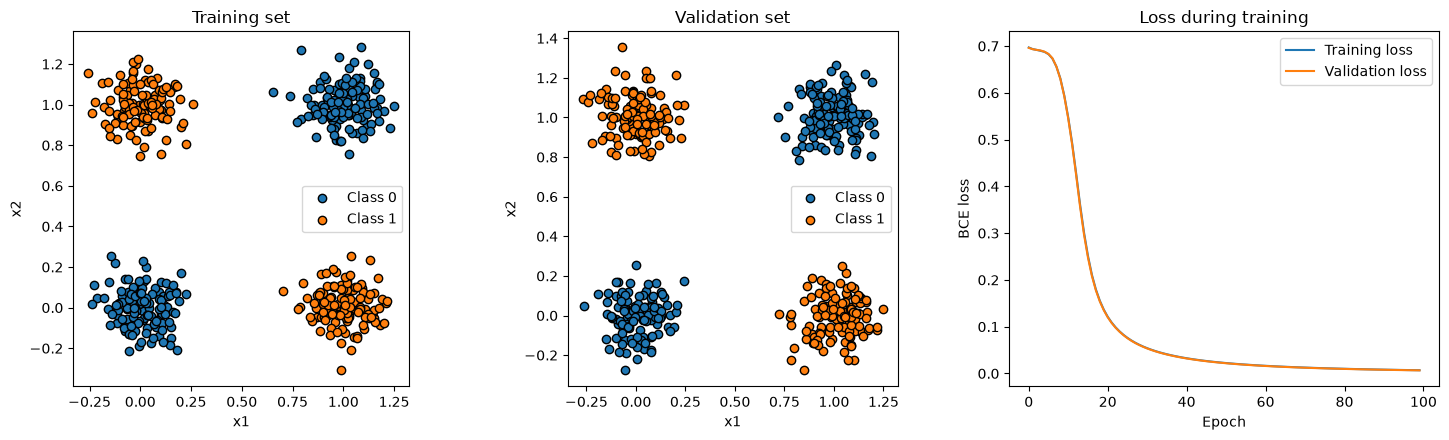

In [6]:
torch.manual_seed(0)                       # for reproducible results

s = 0.1                                    # noise standard deviation
train_set = NoisyXOR(n_samples=500, s=s)
val_set = NoisyXOR(n_samples=500, s=s)     # new, independent data

model = Net(n_hidden_layers=1, width=3)
print(model)

train_losses, val_losses = train(model, train_set, val_set, epochs=100, lr=0.01, batch_size=32)
print(f"Final training loss:   {train_losses[-1]:.4f}")
print(f"Final validation loss: {val_losses[-1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_dataset(axes[0], train_set, "Training set")
plot_dataset(axes[1], val_set, "Validation set")
plot_losses(axes[2], train_losses, val_losses)
plt.tight_layout()
plt.show()